# Application: Stellar Colors

Stellar colors are expressed as the difference in [astronomical
magnitudes](https://en.wikipedia.org/wiki/Magnitude_(astronomy))
with the flux measured through different filters.

The standard [photometric system](https://en.wikipedia.org/wiki/Photometric_system)
defines U, B, V, and more filters, where U is ultraviolet, B is blue, and V
from which we can define a [color index](https://en.wikipedia.org/wiki/Color_index)
like $B-V$ (where here, $B$ is now the magnitude of the star through the B filter).

```{note}
It is $B-V$ that traditionally appears as the $x$-axis in the
[Hertzsprung-Russel diagram](
https://en.wikipedia.org/wiki/Hertzsprung%E2%80%93Russell_diagram).
```

$B-V$ is a difference in magnitudes, which can be expressed as:

$$B - V = -2.5 \log_{10}(f_B/f_V)$$

where $f_B$ is the flux received from a star through the B filter and $f_V$
is the flux from a star through the V filter.

We can treat a star as a perfect blackbody (narrator: they are not), and then
take

$$f_X \approx \int_0^\infty B_\lambda(T) s_X(\lambda) d\lambda$$

where $B_\lambda(T)$ is the Planck function for temperature $T$, and $s_X$ is the filter X's response
(I know, too many things are getting called B...).
The "$\approx$" here is because the distance to the star, its radius, and the fact that we need to
integrate the Planck function over the outward angles all introduce a proportionality constant.  However, since
we are taking the ratio of fluxes, this proportionality constant will cancel.


## Simple box filter

We will take the filter to be a box-filter, with:

$$s_X(\lambda) = \left \{ \begin{array}{cc} 1 & |\lambda - \lambda_{0,X}| \le  \frac{d\lambda_X}{2} \\
                                               0 & \mbox{otherwise} \end{array} \right . $$

(i.e., the filter only lets light through in a narrow band of width $d\lambda_X$
centered on a wavelength $\lambda_{0,X}$.)  Reasonable values for the filter properties
are:

| filter   | $\lambda_{0,X}$  | $d\lambda_{X}$  |
|----------|------------------|-----------------|
|  B       |    445 nm        |     90 nm       |
|  V       |    550 nm        |     90 nm       |
   


## Zero-point

There is one further complication.  Magnitudes have a zero-point (calibration).  It used to be
that Vega was taken to have a magnitude of 0 in all filters (but Vega is variable, so a different
procedure is used now).  

We will assume something Vega-like, and define $B - V = 0$ for $T = 10000~\mathrm{K}$.
This means that you will need to shift your results by a constant offset.


## Implementation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

Let's start by defining the Planck function.  We'll work in CGS units (unlike in class where we made this dimensionless).

In [2]:
def B(lam, T=1.e4):
    """Planck function.  Here lambda is wavelength in cm,
    T is temperature in K"""
    k = 1.38e-16
    h = 6.63e-27
    c = 3.e10
    # we need to take the limit x -> 0 if the input x is 0
    return np.where(lam == 0, 0,
                    2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))

```{tip}
I am using `np.expm1()` here, which is a more accurate way of computing $e^x - 1$ for small $x$.
```

Let's just make sure that our $B(\lambda)$ looks like it should.  For $T = 10^4~\mathrm{K}$, it should peak in the visible.

/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: overflow encountered in expm1
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))


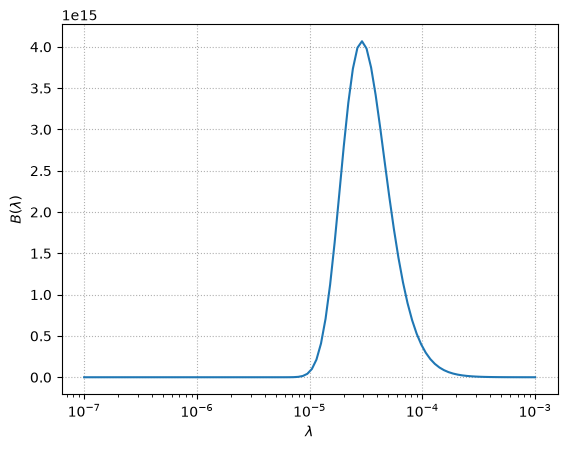

In [3]:
fig, ax = plt.subplots()

T = 1.e4
lam = np.logspace(-7, -3, 100)

ax.plot(lam, B(lam, T))
ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$B(\lambda)$")
ax.grid(ls=":")

Now let's define the filters (I'll include U here for fun).  This stores $\lambda_0$ and $d\lambda$ for each filter in a `dict` keyed on the filter name.

In [4]:
filters = {"U": (365e-7, 70e-7),
           "B": (445e-7, 90e-7),
           "V": (550e-7, 90e-7)}

Next, we'll write a function that computes the filter's response.

In [5]:
def filter_response(lam, lambda0, dlambda=50e-7):
    return np.where(np.logical_and(lam > lambda0-0.5*dlambda,
                                   lam < lambda0+0.5*dlambda), 1.0, 0.0)

and then a function that combines the filter and the Planck function --- this will be our integrand.

```{note}
I use a `*` here on the tuple that holds the filter parameters---this is an example of the [python unpacking operator](https://docs.python.org/3/tutorial/controlflow.html#tut-unpacking-arguments).
```

In [6]:
def filtered_B(lam, T=1.e4, filter="B"):
    return B(lam, T=T) * filter_response(lam, *filters[filter])

Now let's plot this filtered Planck function to see what it looks like.

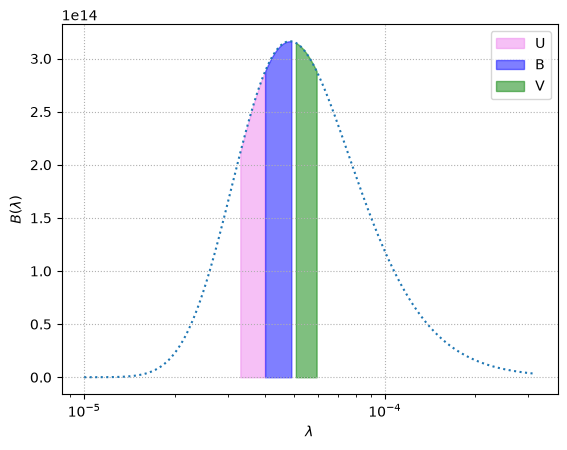

In [7]:
T = 6000

lam = np.logspace(-5, -3.5, 1000)

fig, ax = plt.subplots()

window = filtered_B(lam, T=T, filter="U")
idx = np.where(window != 0.0)
ax.fill_between(lam[idx], window[idx],
                label="U", color="violet", alpha=0.5)

window = filtered_B(lam, T=T, filter="B")
idx = np.where(window != 0.0)
ax.fill_between(lam[idx], window[idx],
                label="B", color="blue", alpha=0.5)

window = filtered_B(lam, T=T, filter="V")
idx = np.where(window != 0.0)
ax.fill_between(lam[idx], window[idx],
                label="V", color="green", alpha=0.5)

ax.plot(lam, B(lam, T=T), ls=":")

ax.set_xscale("log")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$B(\lambda)$")
ax.legend()
ax.grid(ls=":")

### Integrating

We have different options for doing the integrals.  Since our $s(x)$ is just a step function, we actually need to just integrate:

$$f_X \approx \int_{\lambda_{0,X} - d\lambda_X/2}^{\lambda_{0,X} + d\lambda_X/2} B_\lambda(T) s_X(\lambda) d\lambda$$

so we don't need to use the machinery we developed in class for dealing with integrals to $\infty$.

I'll still use that here though, just because we might want to consider a different filter someday...

Let's define the transform functions and a composite trapezoid rule that works with them:

In [8]:
SMALL = 1.e-30

def zv(x, alpha=1):
    """ transform the variable x -> z """
    return x/(alpha + x) 

def xv(z, alpha=1):
    """ transform back from z -> x """
    return alpha*z/(1.0 - z + SMALL)

In [9]:
def I_t(func, N=10, alpha=5, args=None):
    """composite trapezoid rule for integrating from [0, oo].
    Here N is the number of intervals"""

    if args is None:
        args = ()
        
    # there are N+1 points corresponding to N intervals
    z = np.linspace(0.0, 1.0, N+1, endpoint=True)
    
    I = 0.0
    for n in range(N):
        I += 0.5 * ((z[n+1] - z[n]) *
                    (func(xv(z[n], alpha), *args) / (1.0 - z[n] + SMALL)**2 +
                     func(xv(z[n+1], alpha), *args) / (1.0 - z[n+1] + SMALL)**2))
    I *= alpha
    return I

Now, we want to compute the zero-point of $B-V$ as that of a $T = 10^4~\mathrm{K}$ star.  We'll call this `BV0`:

In [10]:
T = 10000
BV0 = -2.5*np.log10(I_t(filtered_B, N=250,
                        alpha=filters["B"][0], args=(T, "B")) /
                    I_t(filtered_B, N=250,
                        alpha=filters["V"][0], args=(T, "V")))

/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))
/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: invalid value encountered in scalar divide
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))
/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: overflow encountered in expm1
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))


Finally, let's compute all of the $B-V$ for different $T$, making sure to correct with `BV0`:

In [11]:
Ts = np.logspace(np.log10(4000), np.log10(30000), 25)
BVs = []

for T in Ts:
    BV = -2.5*np.log10(I_t(filtered_B, N=250,
                           alpha=filters["B"][0], args=(T, "B")) /
                       I_t(filtered_B, N=250,
                           alpha=filters["V"][0], args=(T, "V"))) - BV0
    BVs.append(BV)

/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: divide by zero encountered in scalar divide
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))
/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: invalid value encountered in scalar divide
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))
/tmp/ipykernel_3379485/55925149.py:9: RuntimeWarning: overflow encountered in expm1
  2 * h * c**2 / lam**5 / np.expm1(h*c/(lam*k*T)))


Text(0, 0.5, '$B-V$')

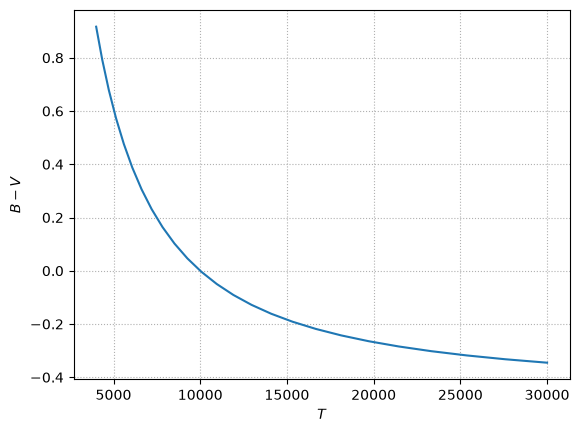

In [12]:
fig, ax = plt.subplots()
ax.plot(Ts, BVs)
ax.grid(ls=":")
ax.set_xlabel("$T$")
ax.set_ylabel("$B-V$")

 and we'll add points for real stars

In [13]:
stars = [("B0", 30000, -0.30),
         ("A0", 9520, -0.02),
         ("F0", 7200, +0.30),
         ("G0", 6030, +0.58),
         ("K0", 5250, +0.81),
         ("M0", 3850, +1.40)]

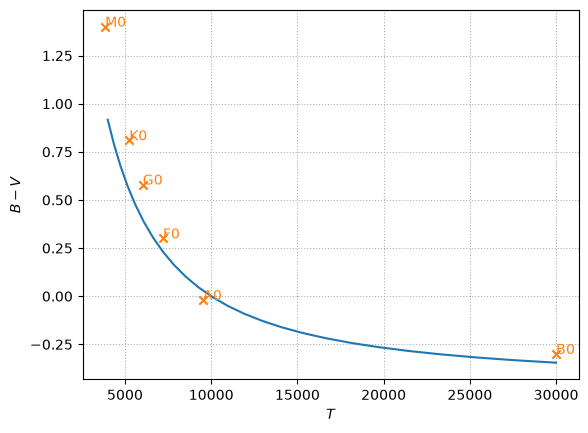

In [14]:
for l, T, BV in stars:
    ax.scatter(T, BV, marker="x", color="C1")
    ax.text(T, BV, l, color="C1")
fig

```{caution}
You may have thought that you could just use `scipy.integrate.quad` to do the
integration from $[0, \infty]$, but it doesn't get the right answer.
```

In [15]:
from scipy import integrate
T = 1.e4
I, err = integrate.quad(filtered_B, 0, np.inf, args=(T, "B"))
I

0.0

The issue here is that our integrand peaks at $\lambda \sim 10^{-5}~\mathrm{cm}$
and the `quad()` function simply does not notice this.  We should instead make
the integrand dimensionless so the peak is near 1.  We accomplished this manually
with our choice of $\alpha$ in our method.

We can get do better if we restrict the integration limits

In [16]:
I, err = integrate.quad(filtered_B, 5.e-6, 2.e-4,
                        limit=100, args=(T, "B"))
I

25172574924.31746

But we really need to make the integrand dimensionless to get the best result
here.